# What is hidden inside a Martian meteorite?

You are operating the ODIN imaging instrument at ESS. Behind this page, a simulation of the instrument produces your
measurements, in the formats of the real instrument.

**Your mission.** You work for a team of planetary scientists. The meteorite NWA 7034 ("Black Beauty"), found in the
Sahara in 2011, is a piece of the Martian crust 4.4 billion years old, and it holds more water than any other Martian
meteorite: about 6 000 ppm, bound in its minerals, a record of the water of early Mars. The team wants to know **where
the water is**: spread evenly, or concentrated in some of the rock fragments (clasts) that make up the meteorite? A
gram of it is worth more than a gram of gold: you must find out **without cutting it**, and tell the team how much
water the richest regions hold (part 6).

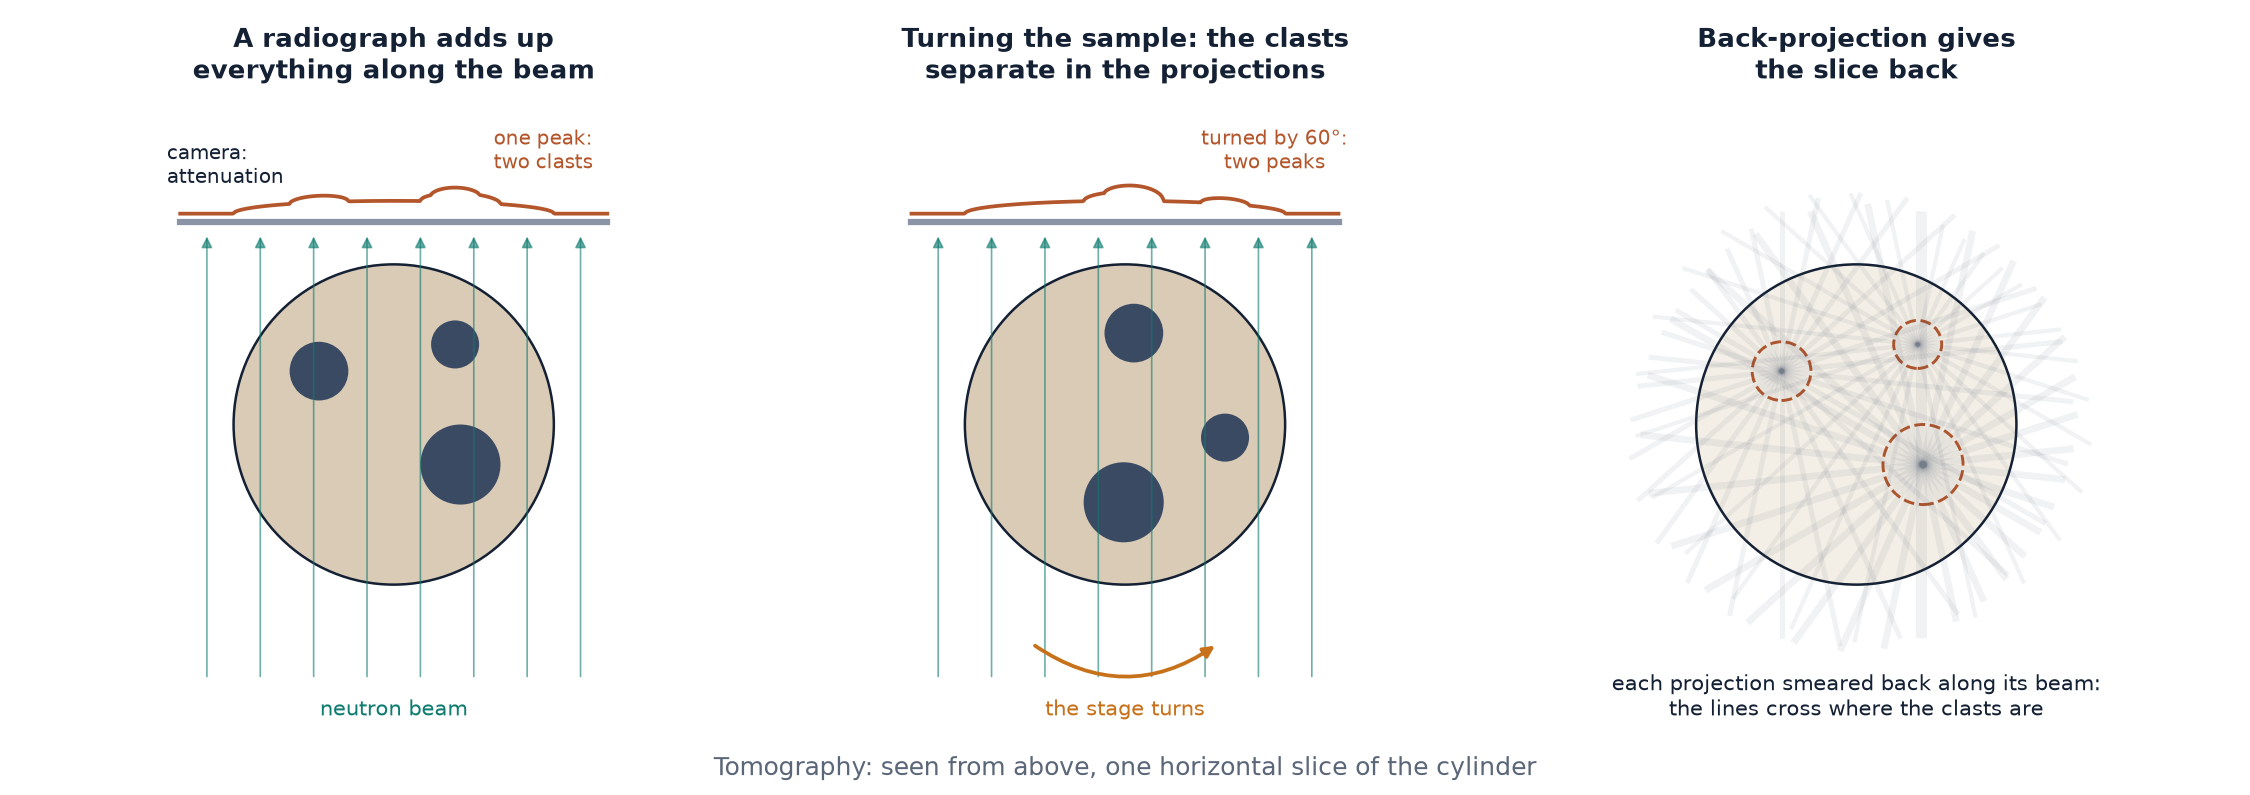

*A radiograph adds up everything along the beam (left): two clasts one behind the other make one spot. Turning the sample and taking radiographs over 180° (middle) gives back each slice by filtered back-projection (right).*

**The sample is real.** A piece of NWA 7034 of 12 × 8 × 2 mm³ was imaged with neutrons at the ICON instrument (PSI)
and with X-rays at the ESRF by E. B. Naver, K. W. Nikolajsen *et al.*, *Direct detection of hydrogen reveals a new
macroscopic crustal water reservoir on early Mars*, arXiv:2601.08390 (2026). The twin uses a model of that piece
built from their numbers: its size, its four kinds of material, their sizes and amounts, and the neutron attenuations
they measured. You will redo their measurement on ODIN, and compare.

**Why neutrons.** X-rays are stopped by heavy atoms (iron, titanium) and hardly see hydrogen. Neutrons do the
opposite: **hydrogen** scatters them more than any other element, while silicon, oxygen, aluminum or iron let them
through. In a neutron image, the hydrogen of the water stands out.

**What you will measure.** A beam goes through the sample; the fraction that comes out, the **transmission**, is

$$T = \frac{I}{I_0} = e^{-\Sigma L}$$

with $L$ the thickness crossed and $\Sigma$ the **attenuation coefficient** of the material (in cm⁻¹). The camera
records $T$ for each pixel: a **radiograph** (parts 1 to 3). A radiograph adds up everything along the beam; turning
the sample and taking radiographs at many angles gives back $\Sigma$ at every point inside: a **tomography** (part 4).
The value of $\Sigma$ then tells what the material is (part 5).

**Questions along the page** check each step: answer in the box, then click *Check*. A wrong answer is explained;
after a try you can also show the answer. Your answers are kept.

In [ ]:
import sys, os, json, warnings
warnings.filterwarnings("ignore")
sys.path[:0] = [os.path.abspath("../../.."), os.path.abspath("../..")]     # twin/ and twin/odin/
import web_user
web_user.sign_in()            # the online version: the anonymous student of the start page (nothing to do in the app)
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, clear_output
from odin_virtual import VirtualOdin
import odin_radiography as tomo
import live_view
from page_output import into
import quiz
q = quiz.Quiz("odin_meteorite_bsc")      # the questions, along the page

SAMPLE = "meteorite_nwa7034"
odin = VirtualOdin(session=os.environ.get("ODIN_SESSION", "student"))
odin.move(sample=SAMPLE)
EXT = tomo.extent()
SETUPS = {"standard": (128, 0.03), "high resolution": (512, 0.01)}     # camera pixels, pinhole

## 0. Your sample

A flat piece **12 mm high, 8 mm wide and 2 mm thick**, standing on the rotation stage of ODIN: at 0° the beam crosses
its 2 mm thickness. Naver *et al.* found four kinds of material in it:

| Material | What it is | Size |
|---|---|---|
| matrix | fine grains (pyroxene, plagioclase, Fe oxides, phosphate), mixed below the resolution | — |
| feldspar | elongated grains | up to 0.1 × 0.44 × 0.15 mm |
| Fe-Ti oxides | grains of magnetite and ilmenite | 3 % of the volume, mostly very fine |
| H-rich Fe-oxyhydroxides | inside lithic clasts of 0.12 to 0.38 mm | 0.4 % of the volume, in clusters |

The camera is just behind the sample and looks along the beam: horizontal axis $x$, vertical axis $y$, field 14 mm.

In [ ]:
spec = odin.sample_spec(SAMPLE)
smp_out = w.Output()
import sample_library as sl
with into(smp_out):
    sl.draw("odin", spec, hidden=["inclusions"], fig=plt.figure(figsize=(10, 3.6)))
    sl.show()
display(smp_out)

## 1. Operate the instrument: radiographs

ODIN is set for **white-beam imaging**: the choppers are stopped (all the wavelengths, the highest flux), and the images
are taken with a camera that integrates the light of a scintillator screen. Two setups:

| Setup | Camera | Pinhole D | Blur | Neutrons per pixel and second |
|---|---|---|---|---|
| **standard** | 128 × 128 pixels of 110 µm, thick bright scintillator | 3 cm | about 0.15 mm | about 900 |
| **high resolution** | 512 × 512 pixels of 27.5 µm, thin scintillator | 1 cm | about 0.05 mm | about 10 |

The blur comes mostly from the pinhole: seen from the camera, 5 cm behind the sample, the pinhole 10.5 m away makes
each point of the sample a spot of size $l \cdot D / L$ (part 3 of the introduction to ODIN). The clasts you are
looking for are 0.1 to 0.4 mm.

**A. A first look** with the standard setup (10 s each): a **dark** (shutter closed: the signal of the camera without
neutrons), an **open beam** (sample out: stage at 500 mm), then the **sample** at 0°.

**B. The real measurement** with the high-resolution setup: dark **300 s**, open beam **1500 s**, sample **300 s**.
The open beam is long on purpose: it divides every image, so its own noise would be printed on all of them (part 4).

In [ ]:
st = odin.status()
setup = w.ToggleButtons(options=list(SETUPS), value="standard", description="Setup")
shut = w.ToggleButtons(options=[("closed", "closed"), ("open", "open")], value=st["shutter"], description="Shutter")
inout = w.ToggleButtons(options=[("in", 0.0), ("out", 0.5)], value=0.0 if abs(st["stage_x"]) < 0.02 else 0.5,
                        description="Sample")
expo = w.Dropdown(options=[10, 30, 300, 1500], value=10, description="Exposure (s)")
title = w.Text(value="", placeholder="e.g. open beam", description="Title")
button = w.Button(description="Take image", button_style="primary", icon="camera", layout=w.Layout(width="auto"))
out = w.Output()
img_take = live_view.FigureImage()

def default_title():
    if shut.value == "closed":
        return f"dark ({setup.value})"
    return f"open beam ({setup.value})" if inout.value > 0.02 else f"meteorite 0° ({setup.value})"

def take(_):
    button.disabled = True
    with out:
        clear_output()
        try:
            px, D = SETUPS[setup.value]
            odin.move(choppers="white", pinhole=D, diffuser="in", shutter=shut.value, stage_x=inout.value,
                      stage_rot=0.0, sample=SAMPLE)
            print("Taking the image (the first one takes a few seconds: the beam is prepared)...")
            f = odin.camera(float(expo.value), title=title.value or default_title(), pixels=px)
            clear_output()
            with img_take:
                fig, ax = plt.subplots(figsize=(5.2, 4.4))
                im = ax.imshow(odin.last_image, origin="lower", extent=EXT, cmap="gray")
                fig.colorbar(im, ax=ax, label="counts per pixel")
                ax.set(xlabel="x (mm)", ylabel="y (mm)", title=f"{os.path.basename(f)}: {title.value or default_title()}")
                plt.tight_layout()
        except Exception as e:
            print("Error:", e)
    button.disabled = False
    refresh_list()

button.on_click(take)
display(w.VBox([setup, shut, inout, expo, title, button, out, img_take]))

## 2. Your measurements

Each image is a numbered file, as on the real instrument; the table is your logbook.

In [ ]:
listing = w.Output()

def measurements():
    ms = []
    if os.path.isfile(odin.log_file):
        for l in open(odin.log_file, encoding="utf-8"):
            e = json.loads(l)
            if e["action"] != "camera" or not e["details"].get("file"):
                continue
            d = e["details"]; s = d["state"]
            if s.get("sample") != SAMPLE:
                continue
            kind = "dark" if s["shutter"] == "closed" else ("open beam" if abs(s["stage_x"]) > 0.02 else "sample")
            px = d.get("pixels", 128)
            ms.append(dict(file=d["file"], path=os.path.join(odin.folder, d["file"]), title=d["title"], t=d["t"],
                           kind=kind, rot=float(s["stage_rot"]), counts=d["n_counts"], pixels=px,
                           setup="high resolution" if px == 512 and abs(s["pinhole"] - 0.01) < 1e-6 else
                                 ("standard" if px == 128 and abs(s["pinhole"] - 0.03) < 1e-6 else "other")))
    return ms

def label(m):
    return f"{m['file']}: {m['title'] or '(no title)'} ({m['t']:g} s)"

def refresh_list():
    ms = measurements()
    of = lambda kind: [(label(m), m["path"]) for m in reversed(ms) if m["kind"] == kind and m["setup"] == show_setup.value
                       and not m["title"].startswith("tomography")]
    for dd, opts in ((pick_S, of("sample")), (pick_O, of("open beam")), (pick_D, of("dark"))):
        dd.options = opts
        if opts:
            dd.value = opts[0][1]
    with into(listing):
        n_tomo = sum(m["title"].startswith("tomography") for m in ms)
        if not ms:
            print("No image yet.")
        for m in ms:
            if not m["title"].startswith("tomography"):
                print(f"{m['file']}  {m['title'] or '(no title)':34s} {m['kind']:10s} t = {m['t']:5g} s  "
                      f"{m['setup']:16s} -> {m['counts']:,} counts")
        if n_tomo:
            print(f"... and {n_tomo} images of tomography (part 4)")

wide = w.Layout(width="560px")
show_setup = w.ToggleButtons(options=list(SETUPS), value="standard", description="Setup")
pick_S = w.Dropdown(description="Radiograph", layout=wide)
pick_O = w.Dropdown(description="Open beam", layout=wide)
pick_D = w.Dropdown(description="Dark", layout=wide)
show_setup.observe(lambda c: refresh_list(), "value")
refresh_list()
display(listing)

## 3. The radiograph

*Show the transmission* computes $T = (I - D)/(O - D)$ for each pixel (each image per second of exposure). Choose the
setup of the images to compare. The profile follows one horizontal line of pixels (choose its height).

In [ ]:
height = w.FloatSlider(value=4.6, min=-6.5, max=6.5, step=0.05, description="Line y (mm)", continuous_update=True,
                       layout=w.Layout(width="420px"))
button_T = w.Button(description="Show the transmission", button_style="success", icon="image", layout=w.Layout(width="auto"))
out_T = w.Output()
img_T = live_view.FigureImage()

def chosen():
    if not (pick_S.value and pick_O.value):
        raise ValueError("Take first an open beam and a radiograph of the meteorite with this setup (part 1).")
    return pick_S.value, pick_O.value, pick_D.value

def show_T(_=None):
    with out_T:
        clear_output()
        try:
            S, O, D = chosen()
            T = tomo.transmission(S, O, D)
            n = T.shape[0]
            with img_T:
                fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1, 1.25]))
                im = a.imshow(T, origin="lower", extent=EXT, cmap="gray", vmin=0.8, vmax=1.0)
                fig.colorbar(im, ax=a, label="transmission T")
                a.axhline(height.value, color="tab:orange", lw=1)
                a.set(xlabel="x (mm)", ylabel="y (mm)", title=f"Transmission ({show_setup.value}, {n} × {n} pixels)")
                row = int(np.clip(round(height.value / tomo.pixel_mm(n) + (n - 1) / 2), 0, n - 1))
                x = np.linspace(EXT[0], EXT[1], n)
                b.plot(x, T[row], color="tab:orange", lw=0.8)
                b.set(xlabel="x (mm)", ylabel="transmission T", title=f"Profile at y = {height.value:.2f} mm",
                      ylim=(0.75, 1.05), xlim=(-5, 5))
                b.grid(alpha=0.3)
                plt.tight_layout()
            if D is None:
                print("Note: no dark image, the dark signal of the camera is not subtracted.")
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)

button_T.on_click(show_T)
height.observe(live_view.throttled(lambda: show_T() if img_T.value else None), "value")
display(w.VBox([show_setup, pick_S, pick_O, pick_D, w.HBox([button_T, height]), out_T, img_T]))

In [ ]:
q.choice("With the **standard** setup, can the radiograph show the clasts of 0.1 to 0.4 mm?",
         ["Hardly: they are as small as the blur (0.15 mm) and the pixels (0.11 mm), and their contrast of a few % is "
          "lost in the noise.",
          "Yes, clearly: neutrons see hydrogen very well.",
          "No: neutrons do not see rocks.",
          "Yes, but only at 90°."],
         answer=0, why={1: "Hydrogen gives contrast, but the clasts are tiny and the 2 mm of rock around them is added "
                           "on each line of sight.",
                        2: "The rock lets 89 % of the neutrons through: it is seen, as a uniform grey.",
                        3: "At 90° the beam crosses 8 mm of rock: even less contrast for a small clast."},
         explanation="To see a 0.2 mm clast, the blur and the pixels must be well below 0.2 mm, and enough neutrons must "
                     "be counted to see a contrast of a few %: hence the high-resolution setup and long exposures.",
         hints=["Compare the size of the clasts with the blur and the pixels of the table of part 1."],
         title="Q1. The standard setup")

In [ ]:
q.number("The blur of the high-resolution setup: $l \\cdot D / L$ with $l$ = 5 cm (sample to camera), D = 1 cm, "
         "L = 10.5 m. How many micrometers?", value=48, tol=3, unit="µm",
         mistakes=[(143, "this is the blur with the 3 cm pinhole"), (0.048, "right, but in mm; the answer is asked in µm")],
         hints=["5 cm × 1 cm / 1050 cm, in cm; then × 10 000 for µm."],
         explanation="0.05 m × 0.01 m / 10.5 m = 4.8·10⁻⁵ m = 48 µm. Three times sharper than with 3 cm, but 9 times "
                     "fewer neutrons (the area of the pinhole): longer exposures.", title="Q2. The blur")

**Reading the radiograph.** About 89 % of the neutrons cross the 2 mm of rock: rocks are almost transparent to
neutrons. With the standard setup the piece looks uniform: the clasts are as small as the blur and the pixels, and
their contrast (a few %) is hidden in the noise. With the high-resolution setup small darker and brighter specks
appear, but a radiograph adds up the whole 2 mm: a speck can be one grain or several, near the front or the back.

## 4. The tomography

*Run the tomography* turns the sample in steps of 3° over 180° and takes one high-resolution image of 300 s at each
angle: 60 images, **5 hours of beam** (the twin computes them in about two minutes). Then, for each horizontal row of
pixels, the projections $-\ln T$ at all the angles are **filtered** and **smeared back** along the direction they were
taken in (filtered back-projection): this gives $\Sigma$ at each point of the slice. For comparison, Naver *et al.*
took 1125 images of 4 minutes at ICON (75 hours), with pixels of 6.2 µm.

In [ ]:
button_tomo = w.Button(description="Run the tomography", button_style="primary", icon="sync", layout=w.Layout(width="auto"))
bar = w.IntProgress(value=0, min=0, max=60, description="Images", layout=w.Layout(width="420px"))
out_tomo = w.Output()
REC = {}

def run_tomo(_):
    button_tomo.disabled = True
    with out_tomo:
        clear_output()
        try:
            show_setup.value = "high resolution"
            refresh_list()
            _, O, D = chosen()
            angles = np.arange(0, 180, 3.0)
            bar.max, bar.value = len(angles), 0
            px, Dp = SETUPS["high resolution"]
            odin.move(choppers="white", pinhole=Dp, diffuser="in", shutter="open", stage_x=0.0, sample=SAMPLE)
            files = odin.tomography(angles, 300.0, title="tomography", pixels=px,
                                    progress=lambda k, n, f: setattr(bar, "value", k))
            odin.move(stage_rot=0.0)
            print("Filtering the projections...")
            REC["rec"] = tomo.Reconstruction(files, O, D)
            clear_output()
            print(f"{len(angles)} images reconstructed. Explore the slices below.")
            show_slices()
        except Exception as err:
            clear_output()
            print("Not possible yet:", err)
    button_tomo.disabled = False
    refresh_list()

button_tomo.on_click(run_tomo)
display(w.VBox([button_tomo, bar, out_tomo]))

**Look inside.** Left: a **horizontal slice** at the height $y$ you choose, seen from above ($x$ across, $z$ the depth
along the beam at 0°). Right: a **vertical slice** at the depth $z$ you choose (as a radiograph, but only that slice).
The color is $\Sigma$ in cm⁻¹. The rings centered on the rotation axis are an artifact: the noise of the open beam,
the same in every projection. Move the sliders through the piece; the largest clasts are near the top.

In [ ]:
ys = w.FloatSlider(value=4.6, min=-6.0, max=6.0, step=0.0275, description="Height y (mm)", continuous_update=True,
                   readout_format=".2f", layout=w.Layout(width="460px"))
zs = w.FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.0275, description="Depth z (mm)", continuous_update=True,
                   readout_format=".2f", layout=w.Layout(width="460px"))
xs = w.FloatSlider(value=0.0, min=-4.0, max=4.0, step=0.0275, description="Point x (mm)", continuous_update=True,
                   readout_format=".2f", layout=w.Layout(width="460px"))
img_sl = live_view.FigureImage()
txt_sl = w.HTML("Run the tomography first.")

def show_slices(_=None):
    if "rec" not in REC:
        return
    r = REC["rec"]
    h, v = r.horizontal(ys.value), r.vertical(zs.value)
    with img_sl:
        fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
        kw = dict(origin="lower", extent=EXT, cmap="magma", vmin=0, vmax=2.0)
        im = a.imshow(h, **kw)
        a.set(xlim=(-4.6, 4.6), ylim=(-1.6, 1.6), xlabel="x (mm)", ylabel="depth z (mm)",
              title=f"Horizontal slice at y = {ys.value:.2f} mm")
        a.axhline(zs.value, color="w", lw=0.6, ls="--"); a.plot(xs.value, zs.value, "c+", ms=14, mew=1.5)
        b.imshow(v, **kw)
        b.set(xlim=(-4.6, 4.6), ylim=(-6.6, 6.6), xlabel="x (mm)", ylabel="y (mm)",
              title=f"Vertical slice at depth z = {zs.value:.2f} mm")
        b.axhline(ys.value, color="w", lw=0.6, ls="--"); b.plot(xs.value, ys.value, "c+", ms=10, mew=1.5)
        fig.colorbar(im, ax=[a, b], label="Σ (cm⁻¹)", shrink=0.8)
    txt_sl.value = "Move the cross (+) onto a bright spot with the three sliders: part 5 measures Σ there."

for s_ in (ys, zs, xs):
    s_.observe(live_view.throttled(show_slices), "value")
display(w.VBox([ys, zs, xs, img_sl, txt_sl]))
show_slices()

In [ ]:
q.choice("Why must the **open beam** be measured much longer than each image of the tomography?",
         ["Every image is divided by the same open beam: its noise is printed identically on all of them and becomes "
          "rings around the rotation axis.",
          "Because the open beam is brighter.",
          "To use more beam time.",
          "It does not matter."],
         answer=0, why={1: "It is brighter, which helps, but the point is that it is the same in every projection.",
                        2: "Beam time is precious: here it is well spent.",
                        3: "Look at the rings in the slices of part 4."},
         explanation="A noise that changes from image to image averages out in the reconstruction; a noise that is the "
                     "same in all the images (the open beam's, a dead pixel) does not: it draws circles. Long open beams "
                     "(or several) are the standard remedy.", hints=["What do all the projections have in common?"],
         title="Q3. The rings")

In [ ]:
q.number("Σ of the **matrix** in the slices (cm⁻¹, in ODIN's white beam):", value=0.55, tol=0.08, unit="cm⁻¹",
         hints=["Part 5 prints it around the cross; or read the color of the slices far from the bright spots."],
         explanation="About 0.53–0.56 cm⁻¹ in ODIN's beam (0.45 cm⁻¹ measured at ICON, whose beam is warmer).",
         title="Q4. The matrix")

In [ ]:
q.choice("Where is the hydrogen?",
         ["In small bright regions (0.1–0.4 mm) grouped in clusters, not spread evenly.",
          "Evenly in the whole piece.",
          "Only at the surface.",
          "In the large dark regions."],
         answer=0, why={1: "The matrix is uniform, but look at the bright spots.",
                        2: "The bright spots are inside, at all depths.",
                        3: "Dark means a small Σ: little attenuation (feldspar)."},
         explanation="Naver et al. found the H-rich phases in localised macroscopic clusters, 0.4 % of the volume: a "
                     "new kind of water reservoir in the Martian crust.", hints=["Move the height slider through the piece."],
         title="Q5. Where?")

## 5. What is in the bright spots?

*Measure Σ* gives the mean $\Sigma$ in a small ball (0.06 mm radius) around the cross (+) of part 4, and in the matrix
around it (0.4 to 0.6 mm away, the median). Their **ratio** compares the spot with the matrix, almost independently of
the spectrum of the beam. Naver *et al.* computed $\Sigma$ of the minerals of NWA 7034 from their composition (their
Table S1, at 25 meV) and measured the matrix at ICON (0.45 cm⁻¹):

| Material (Naver *et al.*, Table S1) | Σ at 25 meV (cm⁻¹) | ratio to the matrix |
|---|---|---|
| plagioclase (albite, anorthite) | 0.27 – 0.28 | 0.6 |
| pyroxenes (enstatite, diopside, Ca-Fe-Al clinopyroxene) | 0.34 – 0.38 | 0.8 |
| chlorapatite | 0.34 | 0.8 |
| ilmenite | 0.70 | 1.6 |
| magnetite, maghemite | 0.80 – 0.82 | 1.8 |

In [ ]:
button_s = w.Button(description="Measure Σ", button_style="success", icon="crosshairs", layout=w.Layout(width="auto"))
out_s = w.Output()
RES = {}

def measure(_=None):
    with out_s:
        clear_output()
        if "rec" not in REC:
            print("Run the tomography first (part 4)."); return
        r = REC["rec"]
        spot = r.value(xs.value, ys.value, zs.value, 0.06)
        ang = np.linspace(0, 2 * np.pi, 12, endpoint=False)
        ring = [r.value(xs.value + d * np.cos(a), ys.value, float(np.clip(zs.value + d * np.sin(a), -0.85, 0.85)), 0.04)
                for d in (0.4, 0.6) for a in ang]
        mat = float(np.median(ring))
        RES.update(spot=spot, matrix=mat)
        print(f"at x = {xs.value:.2f}, y = {ys.value:.2f}, z = {zs.value:.2f} mm:  Σ = {spot:.2f} cm⁻¹")
        print(f"matrix around it:                       Σ = {mat:.2f} cm⁻¹")
        print(f"ratio spot / matrix = {spot / mat:.1f}")

button_s.on_click(measure)
display(w.VBox([button_s, out_s]))

In [ ]:
q.number("The ratio Σ(spot) / Σ(matrix) of the brightest spot you found:", value=4.0, tol=1.6,
         hints=["Put the cross on the brightest spot of the largest clast (near y = 4.6 mm), then Measure Σ."],
         explanation="About 4 to 5 in the middle of a large H-rich region (Naver et al.: 1.9 / 0.45 = 4.2 at ICON); a "
                     "smaller spot gives less (the blur mixes it with its surroundings).", title="Q6. The ratio")

In [ ]:
q.choice("Which material can attenuate **4 times** more than the matrix?",
         ["Only a hydrogen-bearing one: no anhydrous mineral of the table reaches twice the matrix.",
          "Magnetite: it is the densest.",
          "Feldspar.",
          "Any mineral, if the grain is large enough."],
         answer=0, why={1: "Magnetite is at 1.8 times the matrix, not 4.",
                        2: "Feldspar attenuates less than the matrix (0.6 times).",
                        3: "Σ does not depend on the size of the grain: it is a property of the material."},
         explanation="This is the argument of Naver et al.: the measured attenuation of the H-rich regions (1.9 cm⁻¹) "
                     "exceeds the theoretical value of their minerals without hydrogen (0.61 cm⁻¹); only hydrogen can "
                     "explain the difference.", hints=["Compare your ratio with the last column of the table of part 5."],
         title="Q7. Which element?")

**Reading the numbers.** The values of the twin are higher than those of the table: ODIN's white beam is colder
(mean wavelength 3.3 Å) than ICON's (1.8 Å), and these materials attenuate slow neutrons more. Ratios change much
less. The tomography also blurs a spot of 0.1 to 0.3 mm with its surroundings (the blur, about 0.05 mm, and the
pixels, 0.0275 mm): the value in the middle of a small spot is lower than the true one.

## 6. How much water?

Naver *et al.* "assume that all excess measured neutron attenuation results from the presence of hydrogen". The
parts of the clasts without hydrogen show $\Sigma_\text{clast}$ = 0.57 cm⁻¹ at ICON, that is **0.69 cm⁻¹** in ODIN's
beam (the same minerals, computed with the spectrum of the twin), and liquid water **4.9 cm⁻¹**. The fraction of the
volume of the spot that water would fill is then

$$f = \frac{\Sigma_\text{spot} - \Sigma_\text{clast}}{\Sigma_\text{water}}$$

and, with the density of the region (about 3.0 g/cm³), the water by mass is $f \times 1.0 / 3.0$.

In [ ]:
button_w = w.Button(description="Water in the spot", button_style="success", icon="tint", layout=w.Layout(width="auto"))
out_w = w.Output()
SIG_CLAST, SIG_WATER, RHO = 0.69, 4.9, 3.0

def water(_=None):
    with out_w:
        clear_output()
        if "spot" not in RES:
            print("Measure Σ in a bright spot first (part 5)."); return
        f = (RES["spot"] - SIG_CLAST) / SIG_WATER
        print(f"f = ({RES['spot']:.2f} − {SIG_CLAST}) / {SIG_WATER} = {f:.2f}  ->  water by mass = {100 * f / RHO:.0f} %")
        if f <= 0:
            print("No excess attenuation here: is the cross on a bright spot?")

button_w.on_click(water)
display(w.VBox([button_w, out_w]))

In [ ]:
q.number("The water by mass in the brightest spot (part 6, %):", value=10, tol=6, unit="%",
         hints=["Part 6 computes it from your Σ of part 5."],
         explanation="The model holds about 14 % (Naver et al.: up to 15 wt% OH). The blur lowers Σ in the middle of a "
                     "small region, so the estimate is lower: a few % to about 12 %.", title="Q8. How much water?")

In [ ]:
q.number("Naver et al. estimate that these clasts hold 635 ppm of water, of the 6000 ppm of the whole meteorite. What "
         "share is that (%)?", value=10.6, tol=1.0, unit="%",
         hints=["635 / 6000."], explanation="635 / 6000 = 10.6 %, the 11 % of the paper: a macroscopic reservoir, while "
                                            "most of the water is spread in the fine matrix.", title="Q9. Their share")

In [ ]:
q.choice("**Your report to the team.**",
         ["The water is concentrated in small clasts (0.1–0.4 mm) grouped in clusters; their attenuation can only be "
          "explained by hydrogen, about 10 % water by mass; the tomography gives their positions for sampling.",
          "The water is spread evenly in the meteorite.",
          "There is no water: the bright spots are magnetite.",
          "Neutrons cannot answer: X-rays are needed."],
         answer=0, why={1: "The bright spots are local.", 2: "Magnetite reaches 1.8 times the matrix, not 4.",
                        3: "Neutrons are the right probe for hydrogen; X-rays see the Fe-Ti oxides."},
         explanation="Your conclusion is that of Naver et al. (2026): a new macroscopic crustal water reservoir on early "
                     "Mars, found without cutting the meteorite.", hints=["Q5, Q7 and Q8 together."], title="Q10. The report")

**Limits of the twin.** The piece is a model: its size, the kinds of material, their amounts, sizes and attenuations
are those published by Naver *et al.*; the positions, shapes (ellipsoids) and number of the clasts are drawn at random,
and the hydrogen is represented by an equivalent amount of water (NCrystal). The minerals are mixed at the scale of
each region (no crystal, no Bragg edge). The camera is modeled by its mean signal, its noise and its blur.

## 7. Your results

Your score on the questions of the page, and a report to download.

In [ ]:
q.report()

## 8. Submit your work

When you are done, tell what you thought of the exercise and submit your work.

In [ ]:
import submit
_ = submit.Submit("odin/exercises/meteorite_imaging", "bsc", quiz=q)